In [505]:
from pathlib import Path

import numpy as np
import scipy 
import pandas as pd
from scipy.linalg import svdvals
from matplotlib.ticker import MaxNLocator

import matplotlib.pyplot as plt

%matplotlib inline 

# 1. Preliminary data analysis and explanation

In [506]:
# original data path
csv_path = Path("reproduction_decay_newtrial_diff_all_V15.csv")

df = pd.read_csv(csv_path) # dataframe

print("Number of spike records:", len(df))
print("Number of neurons:", df["cellID"].nunique())
df[0:5]

Number of spike records: 957100
Number of neurons: 331


,Unnamed: 0,spike_time,trial,new_trial,end,duration,cellIndex,cellID,ave_trial_length,sd_trial_length
0,9,0.2387,1,1,4.98326,6.75,11770_9_1_07,331,5.249635,1.333275
1,10,0.4607,1,1,4.98326,6.75,11770_9_1_07,331,5.249635,1.333275
2,11,0.5855,1,1,4.98326,6.75,11770_9_1_07,331,5.249635,1.333275
3,12,3.5211,1,1,4.98326,6.75,11770_9_1_07,331,5.249635,1.333275
4,13,3.5954,1,1,4.98326,6.75,11770_9_1_07,331,5.249635,1.333275


**NOTE:** each trial also has different duration for each neuron. For example, for a duration of 6.75s, cellID = 331 has a trial duration of 6.75 for trial 1 and 4.5 for trial 2.

| Column | Meaning | 
| -------- | -------- | 
| <span style="color: green;">spike_time</span> | spike time of past cells |
| trial    |  original trial number for the recording session | 
| new_trial | trial where neuron doesn't produce a spike is omitted and put as new_trial number |
| <span style="color: red;">end</span>    | animal's predicted duration in the reproduction interval, always bigger than the last spike_time   |
| <span style="color: blue;">duration</span> | target interval the animal was instructed to reproduce |

In [496]:
# for example
df[df['trial'] != df['new_trial']][0:5]

,Unnamed: 0,spike_time,trial,new_trial,end,duration,cellIndex,cellID,ave_trial_length,sd_trial_length
142068,448863,1.06,61,60,7.51656,7.5,11770_54_5_05,299,5.214346,1.215883
142069,448963,2.01,61,60,7.51656,7.5,11770_54_5_05,299,5.214346,1.215883
142070,449063,2.19,61,60,7.51656,7.5,11770_54_5_05,299,5.214346,1.215883
142071,4491113,2.34,61,60,7.51656,7.5,11770_54_5_05,299,5.214346,1.215883
142072,449269,3.16,61,60,7.51656,7.5,11770_54_5_05,299,5.214346,1.215883


original spike timing: [0.2387 0.4607 0.5855 3.5211 3.5954 3.7336]
spike timing for plotting: [0.2387 0.4605 0.5856 3.521  3.5953 3.7338]


Text(0, 0.5, 'spike time (s)')

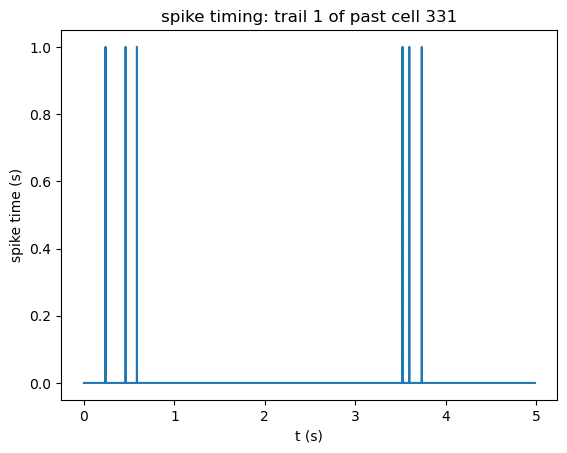

In [497]:
required_columns = ['cellID', 'trial', 'spike_time', 'end', 'duration']
my_df = df[required_columns]

# example of spike of a neuron 
cellID_df = my_df[df['cellID'] == 331]
trial_end = cellID_df[cellID_df['trial'] == 1]['end'].iloc[0]
time = np.linspace(0, trial_end, 10000)
events = np.zeros(time.shape[0])
trail_events = cellID_df['spike_time'][cellID_df['trial'] == 1]
for trail_event in trail_events:
    event_idx = np.abs(time - trail_event).argmin()
    events[event_idx] = 1

print(f'original spike timing: {np.round((cellID_df[cellID_df['trial'] == 1]['spike_time']).values,4)}')
print(f'spike timing for plotting: {np.round(time[np.where(events == 1)],4)}')

plt.plot(time,events)
plt.title('spike timing: trail 1 of past cell 331')
plt.xlabel('t (s)')
plt.ylabel('spike time (s)')

# 2. Get neuron firing rates
Since trials have different <span style="color: blue;">duration</span>, will use a reference <span style="color:blue;">duration</span>, because we want every spike firing start and end at the same interval. We use 5.25s because that is the mean and median of the target reproduction interval, target reproduction interval: [3, 3.75, 4.5, 5.25, 6, 6.75, 7.5]. The reference interval is only for plotting. To get the firing rates, we define the following:
$$
u = \frac{t}{T_{ir}} \in [0, 1]\tag{1} 
$$
where t is <span style="color: green;">spike_time</span> and $T_{ir}$ is <span style="color: red;">end</span> of trial $r$ and neuron $i$. We have a reference bin width of 0.0525 seconds and a reference duration of 5.25 seconds, the actual duration of a bin in trial $r$ is $T_{ir}/100$ because we have 100 bins. For each neuron and trial, we convert count spikes to each bin
$$ r_{ir,j} = 100\frac{\text{number of spikes in bin j}}{T_{ir}} \tag{2}$$
Then we average trials to get a matrix:
$$ R_{ij} = \frac{1}{M_i} \sum^{M_i}_{r = 1}r_{ir,j} \tag{3} $$
where $R_{ij}$ is the trial-averaged firing rates.

index notation:
- i neuron
- j bin
- r trial

In [498]:
n_bins = 200

phase_edges = np.linspace(0.05, 1.0, n_bins + 1)
reference_duration = 5.25
dt_reference = reference_duration / n_bins

time_centers = (
    (phase_edges[:-1] + phase_edges[1:]) / 2
    * reference_duration
) # used for plotting

cell_ids = np.sort(df["cellID"].unique())
trial_rates = []
trial_conditions = []
trial_counts = []

for cell_id in cell_ids:
    # finds all the rows in the dataframe df where it has the cell_id
    cell_data = df.loc[df["cellID"] == cell_id]
    rates_for_cell = []
    conditions_for_cell = []

    for trial_id, trial_data in cell_data.groupby("trial", sort=True):
        # Metadata should be constant within a neuron-trial.
        assert trial_data["end"].nunique() == 1
        assert trial_data["duration"].nunique() == 1

        T = float(trial_data["end"].iloc[0])
        target_duration = float(trial_data["duration"].iloc[0])
        spike_times = trial_data["spike_time"].to_numpy(dtype=float)
        
        # Convert physical spike times to fractional trial progress.
        # Implements equation 1
        spike_phases = spike_times / T # \in [0, 1]

        counts, _ = np.histogram(
            spike_phases,
            bins=phase_edges, # \in [0, 1]
        )

        # Convert counts to spikes per physical second.
        # Implements equation 2, 
        # counts = number of spikes in bin j
        actual_bin_duration = T / n_bins
        firing_rates = counts / actual_bin_duration

        # plt.plot(time_centers, firing_rates)
        # plt.xlabel("Rescaled time (reference seconds)")
        # plt.ylabel("Firing rate (Hz)")
        
        rates_for_cell.append(firing_rates)
        conditions_for_cell.append(target_duration)

    trial_rates.append(np.stack(rates_for_cell))
    trial_conditions.append(np.array(conditions_for_cell))
    trial_counts.append(len(rates_for_cell))

trial_counts = np.array(trial_counts)

# Implements equation 3
# Row i: neuron i
# Column j: time bin j
# R_ij: trial-averaged firing rate
R = np.stack([
    rates.mean(axis=0) # mean across rows
    for rates in trial_rates
])

print("First neuron's trial-rate array:", trial_rates[0].shape)
print("Represented cell-trials:", trial_counts.sum())
print("Population matrix:", R.shape)

First neuron's trial-rate array: (39, 200)
Represented cell-trials: 20814
Population matrix: (331, 200)


Text(0.5, 0, 'time (s)')

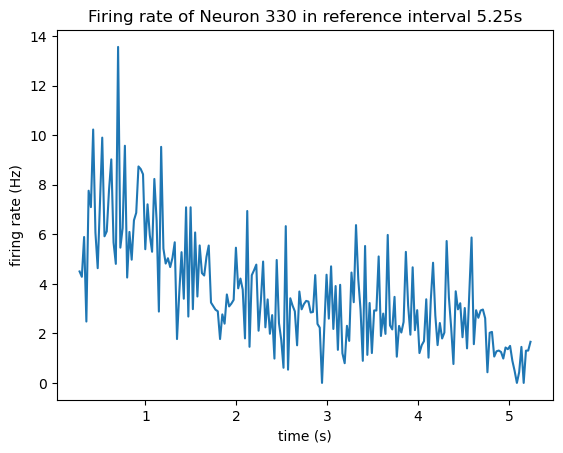

In [499]:
neuron_i = 330
plt.title(f'Firing rate of Neuron {neuron_i} in reference interval 5.25s')
plt.plot(time_centers, R[neuron_i,:])
plt.ylabel('firing rate (Hz)')
plt.xlabel('time (s)')

In [500]:
def exp_decay(t, A, xi, b):
    return A * np.exp(-xi * t) + b

results = []

for i, y in enumerate(R): # i is neuron i, y is firing rate, the data we are going to fit
    try: 
        popt, _ = curve_fit(
            exp_decay,
            time_centers,
            y,
            p0 = [max(y[0] - y[-1], 0.01), 0.01, max(y[-1], 0)],
            bounds = (0, np.inf),
            maxfev = 10000
        )
        y_pred = exp_decay(time_centers, *popt)

        ss_res = np.sum((y_pred - y)**2)
        ss_tot = np.sum((y - y.mean())**2)

        r2 = 1 - ss_res / ss_tot

        results.append([i, *popt, r2])
    except RuntimeError:
        results.append([i, np.nan, np.nan, np.nan, np.nan])

df = pd.DataFrame(
    results,
    columns=["neuron", "A", "xi", "baseline", "R2"]
)
df = df.sort_values("R2", ascending=False)
df_R2 = df['R2'].to_numpy()
print(len(np.where(df_R2 >= 0.4)[0]))

139


# 3. Singular value decomposition
In the discussion of [Ramping cells in the rodent medial prefrontal cortex encode time to past and future events via real Laplace transform
](https://www.pnas.org/doi/10.1073/pnas.2404169121)
It says the pattern of firing of temporal context cells resembles the real Laplace transform of the time since the interval began, which is equation (1) in our paper, 
$$F(\xi_i, t) = \int^t_{-\infty}e^{-\xi_i (t - t')}f(t')dt'$$
As an example, for a given stimulus that starts at $t_0$, we have $f(t') = \delta(t' - t_0)$, where $\delta(t)$ is the unit impulse function, and the firing rate becomes 
$$F(\xi_i, t) = \int^t_{-\infty}e^{-\xi_i(t - t_0)}\delta(t' - t_0)dt' = e^{-\xi_i (t - t_0)}$$
which is a sample of the infinite ramping cell population operator. In our calculated theoretical singular value, we calculated for the finite ramping cell population operator, and we can have $h(t) = \delta(t - t_0)$,
$$\mathcal{T}_c(h) = \int^{T_{\max}}_{T_{\min}} e^{-\xi \tau} \delta(\tau - (t - t_0)  d\tau = e^{-\xi (t - t_0)}$$
since we proved property for any input $h(t)$ to the finite ramping cell population operator. 

Therefore, we will just perform singular value analysis on the matrix $R$, where each row represents the trial-averaging firing rate for temporal context/ramping cell $i$ during the interval reproduction task. For here, each trial, a gerbil experiences a target stimulus duration, and then reproduces the duration by running on a treadmill.

First, we demonstrate the capability of gerbils to precisely measure and reproduce time intervals of several seconds. After the presentation of a black screen, the animals had to reproduce its duration by walking along a corridor in virtual reality. Intervals were randomly sampled between 3 and 7.5 s. 

In [501]:
print(sigma_raw[0], sigma_raw[-1])
print(sigma_raw[-1]/sigma_raw[0])
print(sigma_centered[0], sigma_centered[-1])
print(sigma_centered[-1]/sigma_centered[0])
print('------------------------------------------------')
print(f'{normalized_raw[0]} ... {normalized_raw[-1]}')
print(normalized_raw[-1]/normalized_raw[0])
print(f'{normalized_centered[0]} ... {normalized_centered[-1]}')
print(normalized_centered[-1]/normalized_centered[0])

2297.943092873858 9.315874348643181
0.004054005679049495
425.99649362184346 1.6062485720887722e-13
3.77056758949438e-16
------------------------------------------------
1.0 ... 0.004054005679049495
0.004054005679049495
1.0 ... 3.77056758949438e-16
3.77056758949438e-16


In [504]:
np.linalg.matrix_rank(R), np.where(R_centered < 0)

(np.int64(200),
 (array([  0,   0,   0, ..., 330, 330, 330], shape=(18584,)),
  array([31, 40, 45, ..., 97, 98, 99], shape=(18584,))))

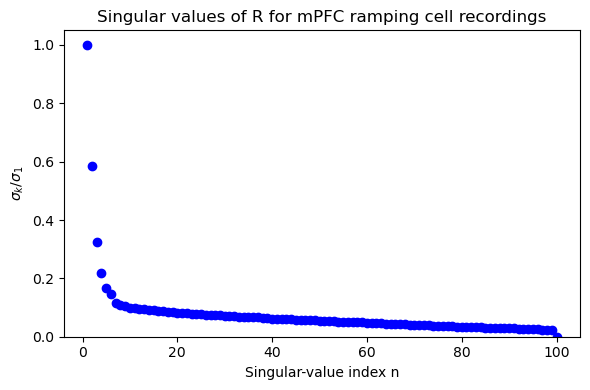

In [461]:
# subtracting the mean normalize the data
# every neuron has a base firing rate 
# if you don't have data without stimulus,
# you can normalize the data by subtracting the mean
neuron_means = R.mean(axis=1, keepdims=True)
R_centered = R - neuron_means

A_raw = R
A_centered = R_centered

sigma_raw = svdvals(A_raw)
sigma_centered = svdvals(A_centered)

normalized_raw = sigma_raw / sigma_raw[0]
normalized_centered = sigma_centered / sigma_centered[0]

n_svd = 100

if n_svd <= 20:
    print(f'First {n_svd} singular values (including mean firing): {np.round(normalized_raw[0:n_svd],2)}')
    print(f'First {n_svd} singular values (temporal mean subtracted: {np.round(normalized_centered[0:n_svd],2)}')

fig, ax = plt.subplots(figsize=(6, 4))

k = np.arange(1, n_svd+1)

# ax.plot(
#     k, normalized_raw[:n_svd], "o-",
#     label="Including mean firing",
# )

ax.plot(
    k, normalized_centered[:n_svd], "bo",
    label="Temporal mean subtracted",
)

ax.set_xlabel("Singular-value index n")
ax.set_ylabel(r"$\sigma_k / \sigma_1$")
ax.set_title(f"Singular values of R for mPFC ramping cell recordings")
# ax.set_xlim(1, n_svd)
ax.set_ylim(bottom=0)
# ax.legend()

plt.tight_layout()
plt.show()

fig.savefig("cao_svd.pdf")

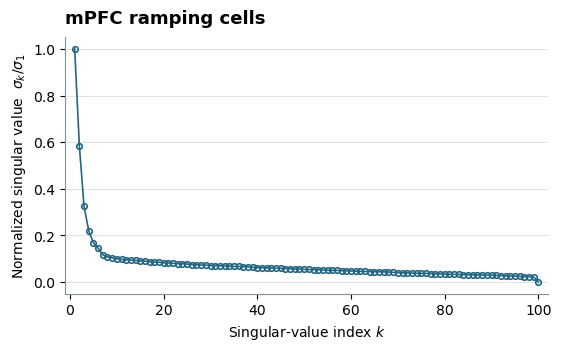

In [462]:
normalized = normalized_centered

# A 331 × 100 matrix has 100 singular values.
n_show = normalized_raw.shape[0]
k = np.arange(1, n_show + 1)

fig, ax = plt.subplots(figsize=(5.5, 3.4), layout="constrained")

ax.plot(
    k, normalized[:n_show],
    color="#246681",
    linewidth=1.2,
    marker="o",
    markersize=4,
    markerfacecolor="none",
    markeredgecolor="#246681",
    markeredgewidth=1.2,
)

ax.set_title("mPFC ramping cells", loc="left", fontsize=13,
             fontweight="bold", pad=10)
ax.set_xlabel(r"Singular-value index $k$")
ax.set_ylabel(r"Normalized singular value  $\sigma_k/\sigma_1$")
ax.set_ylim(-0.05, 1.05)
ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
ax.margins(x=0.02)

ax.set_axisbelow(True)
ax.grid(axis="y", color="#dce3e7", linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#809099")

fig.savefig(f"cao_svd_{n_show}.pdf", bbox_inches="tight")
plt.show()

                Spectrum       Model  Modes        A  Decay_or_exponent      RMSE  R_squared
   Including mean firing Exponential     99 0.997046            1.75407 0.0156034   0.975725
   Including mean firing   Power law     99 0.994976            2.38433 0.0123685   0.984747
Temporal mean subtracted Exponential     99 0.944714           0.421157 0.0565531   0.755248
Temporal mean subtracted   Power law     99 0.960236           0.854129 0.0235944   0.957398


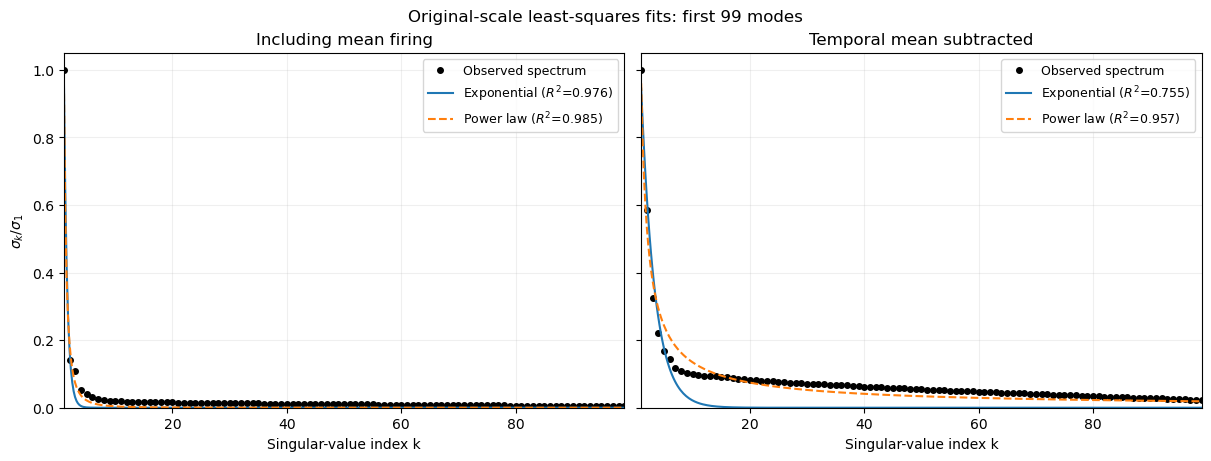

In [446]:
from fit_singular_spectra import fit_spectra

fig, results = fit_spectra(
    sigma_raw,
    sigma_centered,
    n_fit=99,
)

print(results.to_string(index=False, float_format=lambda x: f"{x:.6g}"))
plt.show()